# Module 5 - Big Data Analytics
**What this module covers:** why big-data tools are needed for this dataset, the document vs relational data model,
**MongoDB accident storage** (GeoJSON + 2dsphere index, 10 queries/aggregations timed with and without indexes),
the **Hadoop data flow** with MapReduce (Hadoop Streaming mapper/reducer for three jobs, run locally with the exact
map -> sort -> reduce flow), a three-way cross-check (pandas vs MongoDB vs MapReduce), the optional PySpark code
and the end-to-end data-flow diagram.

**Project tasks satisfied here:** *Big Data: MongoDB accident storage; Hadoop data flow (MapReduce).*

Code: `bigdata/mongodb/`, `bigdata/hadoop_mapreduce/`, `bigdata/spark_optional/` (not executed).

In [1]:
import sys, json, subprocess, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "bigdata" / "mongodb"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from src import utils as U, viz as V
import load_to_mongo, queries

V.apply_style()
MET, FIG = U.METRICS, U.FIGURES
stats_ = U.load_json(MET / "dataset_stats.json")
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| interpreter:", Path(sys.executable).parent.parent.name)

Python 3.14.2 | pandas 3.1.0 | interpreter: .venv


## 1. Why big-data tools?
The three "V"s, measured on this dataset:

In [2]:
raw_gb = U.DATA_RAW.stat().st_size / 1e9
pq_mb = U.CLEAN_PARQUET.stat().st_size / 1e6
blocks = int(np.ceil(U.DATA_RAW.stat().st_size / (128 * 1024 ** 2)))
vt = pd.DataFrame([
    ("Volume", f"{stats_['total_rows']:,} rows x {stats_['total_columns']} columns, {raw_gb:.2f} GB CSV"),
    ("Volume (HDFS view)", f"{blocks} blocks of 128 MB; x3 replication = {3 * blocks} block replicas"),
    ("Velocity", f"records from {stats_['date_min'][:10]} to {stats_['date_max'][:10]}, streamed from traffic APIs"),
    ("Variety", "numeric weather, timestamps, GPS points, categorical text, booleans, free-text descriptions"),
    ("Laptop strategy", f"chunked reads of {stats_['chunksize']:,} rows; columnar Parquet sample = {pq_mb:.1f} MB"),
], columns=["aspect", "this project"])
vt

,aspect,this project
0,Volume,"7,728,394 rows x 46 columns, 3.06 GB CSV"
1,Volume (HDFS view),23 blocks of 128 MB; x3 replication = 69 block...
2,Velocity,"records from 2016-01-14 to 2023-03-31, streame..."
3,Variety,"numeric weather, timestamps, GPS points, categ..."
4,Laptop strategy,"chunked reads of 500,000 rows; columnar Parque..."


Loading the whole CSV into pandas needs several times its size in RAM, so Module 1 streamed it in chunks - the
same *split -> process -> combine* idea that MapReduce and Spark use across machines.

## 2. Document model vs relational model
| | Relational (SQL) | Document (MongoDB) |
|---|---|---|
| Unit | row in a fixed-schema table | JSON/BSON document, flexible fields |
| Missing values | NULL in every row | field simply absent (sparse weather data stores well) |
| Geo data | extension needed (PostGIS) | native GeoJSON + `2dsphere` index, `$geoNear` |
| Joins | normalised tables + joins | related data embedded in one document (accident + weather + road flags) |
| Scale-out | mostly vertical | horizontal sharding, replica sets |
| Best for | transactions, strict integrity | read-heavy analytics on semi-structured events |

An accident is a self-contained event that is written once and read many times, with many optional fields, so a
document store fits it naturally.

## 3. MongoDB - load `traffic_db.accidents`

In [3]:
load_info = load_to_mongo.main()
coll = load_to_mongo.get_client()[load_to_mongo.DB][load_to_mongo.COLL]
doc = coll.find_one({}, {"_id": 1, "Severity": 1, "Start_Time": 1, "City": 1, "State": 1, "WeatherGroup": 1,
                         "Temperature_F": 1, "location": 1, "Junction": 1})
print(json.dumps(doc, default=str, indent=2))

{'database': 'traffic_db', 'collection': 'accidents', 'documents': 399581, 'batch_size': 10000, 'batches': 40, 'load_seconds': 6.2, 'indexes': ['location_2dsphere', 'State_1', 'Severity_1', 'Start_Time_1'], 'storage_size_mb': 45.6, 'avg_doc_bytes': 679, 'server_version': '9.0.4'}
{
  "_id": "A-337795",
  "Severity": 1,
  "Start_Time": "2017-02-22 11:52:04",
  "City": "San Jose",
  "State": "CA",
  "Temperature_F": 55.0,
  "WeatherGroup": "Cloudy",
  "Junction": false,
  "location": {
    "type": "Point",
    "coordinates": [
      -121.904472,
      37.346977
    ]
  }
}


## 4. MongoDB queries and aggregations - timed with and without indexes
Each query runs once to warm up, then 5 times; the median is reported. Then the secondary and 2dsphere indexes are
dropped, the queries are re-run, and the indexes are restored. `plan` is the winning stage from `explain()`.

In [4]:
mres = queries.main()
mres["load"] = load_info
U.save_json(mres, MET / "mongo_results.json")
qt = pd.DataFrame([{k: q[k] for k in ["name", "description", "ms_with_index", "plan_with_index", "ms_without_index", "plan_without_index"]}
                   for q in mres["queries"]])
qt["speedup"] = (qt["ms_without_index"] / qt["ms_with_index"]).round(1)
qt

count_by_state           with index    272.52 ms (COLLSCAN         )  without 253.71 ms


avg_severity_by_weather  with index     329.6 ms (COLLSCAN         )  without 352.2 ms


top_cities               with index    317.42 ms (COLLSCAN         )  without 375.65 ms


hourly_distribution      with index    264.66 ms (COLLSCAN         )  without 269.84 ms


severity_counts          with index    228.31 ms (COLLSCAN         )  without 238.9 ms
geo_near_hotspot         with index     50.38 ms (GEO_NEAR_2DSPHERE)  without None ms


time_range_jan_2022      with index      3.29 ms (IXSCAN           )  without 201.15 ms


ca_severity_4            with index     14.81 ms (IXSCAN           )  without 233.94 ms


top_states_severe        with index    113.86 ms (IXSCAN           )  without 241.43 ms


latest_ny                with index      0.76 ms (IXSCAN           )  without 297.72 ms


,name,description,ms_with_index,plan_with_index,ms_without_index,plan_without_index,speedup
0,count_by_state,Accidents per state ($group + $sort),272.52,COLLSCAN,253.71,COLLSCAN,0.9
1,avg_severity_by_weather,Average severity and count per weather group,329.60,COLLSCAN,352.20,COLLSCAN,1.1
2,top_cities,"Top 10 cities ($group on City+State, $sort, $l...",317.42,COLLSCAN,375.65,COLLSCAN,1.2
3,hourly_distribution,Accidents per hour of day,264.66,COLLSCAN,269.84,COLLSCAN,1.0
4,severity_counts,Accidents per severity level,228.31,COLLSCAN,238.90,COLLSCAN,1.0
5,geo_near_hotspot,$geoNear: accidents within 10 km of the top ho...,50.38,GEO_NEAR_2DSPHERE,NaN,not possible: $geoNear requires the location_2...,NaN
6,time_range_jan_2022,Accidents with Start_Time in January 2022 (ran...,3.29,IXSCAN,201.15,COLLSCAN,61.1
7,ca_severity_4,Severity-4 accidents in California (equality f...,14.81,IXSCAN,233.94,COLLSCAN,15.8
8,top_states_severe,Top 5 states by severe (3-4) accidents ($match...,113.86,IXSCAN,241.43,COLLSCAN,2.1
9,latest_ny,5 most recent accidents in NY (find + sort + l...,0.76,IXSCAN,297.72,COLLSCAN,391.7


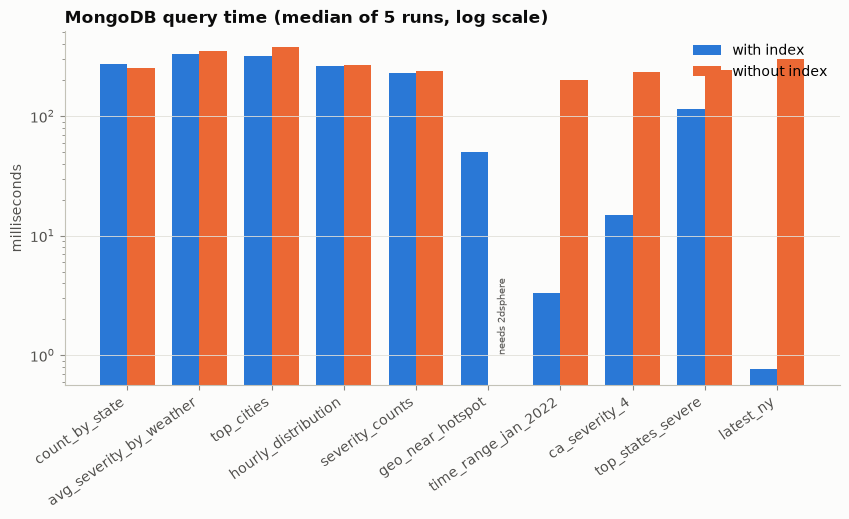

,Severity,accidents,avg_dist_km
0,1,4,7.907118
1,2,4138,5.669471
2,3,1052,5.486786
3,4,32,5.156360


In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(qt)); w = 0.38
ax.bar(x - w / 2, qt["ms_with_index"], w, color=V.PRIMARY, label="with index")
ax.bar(x + w / 2, qt["ms_without_index"].fillna(0), w, color=V.ACCENT, label="without index")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(qt["name"], rotation=35, ha="right")
ax.set(title="MongoDB query time (median of 5 runs, log scale)", ylabel="milliseconds"); ax.legend()
ax.annotate("needs 2dsphere", (x[qt.name == "geo_near_hotspot"][0] + w / 2, 1), ha="center", fontsize=7, color=V.INK2, rotation=90, va="bottom")
V.save(fig, FIG / "mongo_query_timings.png")
geo = next(q for q in mres["queries"] if q["name"] == "geo_near_hotspot")
pd.DataFrame(geo["result"]).rename(columns={"_id": "Severity"})

**Reading the timings:** filters on an indexed field (`time_range_jan_2022`, `ca_severity_4`, `latest_ny`,
`top_states_severe`) switch from a full collection scan (COLLSCAN) to an index scan (IXSCAN). Whole-collection
`$group` aggregations must read every document either way, so an index does not help them - the difference there
is run-to-run noise. `$geoNear` cannot run at all without the 2dsphere index.

## 5. Hadoop data flow - MapReduce with Hadoop Streaming
```
HDFS input (blocks) -> map tasks: mapper.py emits key \t value -> shuffle & sort by key -> reduce tasks:
reducer.py aggregates each key -> HDFS output (part-00000 ...)
```
`run_local.ps1` executes exactly this flow on one machine: `type input | python mapper.py JOB | sort | python reducer.py JOB`.
The optional real-cluster commands (`hdfs dfs -put`, `hadoop jar hadoop-streaming.jar ...`) and a single-node
`docker-compose.yml` are in `bigdata/hadoop_mapreduce/README.md` - **not executed** (no Docker/WSL on this laptop).

In [6]:
mr_dir = ROOT / "bigdata" / "hadoop_mapreduce"
(mr_dir / "input" / "accidents.tsv").unlink(missing_ok=True)
t0 = time.time()
r = subprocess.run(["powershell", "-NoProfile", "-ExecutionPolicy", "Bypass", "-File", str(mr_dir / "run_local.ps1")],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout, r.stderr[-2000:]); assert r.returncode == 0
print(f"total {time.time() - t0:.1f} s")
print("Mapper output sample (first 3 lines of the 'weather' job before sorting):")
head = subprocess.run([sys.executable, str(mr_dir / "mapper.py"), "weather"], input="\n".join(
    (mr_dir / "input" / "accidents.tsv").read_text(encoding="utf-8").splitlines()[:4]) + "\n", capture_output=True, text=True).stdout
print(head)

Wrote bigdata\hadoop_mapreduce\input\accidents.tsv: 399,581 rows
job=state    output=output\state.tsv keys=49 seconds=0.9
job=weather  output=output\weather.tsv keys=7 seconds=1.0
job=hour     output=output\hour.tsv keys=24 seconds=1.0
 
total 4.6 s
Mapper output sample (first 3 lines of the 'weather' job before sorting):
Cloudy	1
Clear	1
Cloudy	1



In [7]:
mr_state = pd.read_csv(mr_dir / "output" / "state.tsv", sep="\t", header=None, names=["State", "accidents"])
mr_weather = pd.read_csv(mr_dir / "output" / "weather.tsv", sep="\t", header=None, names=["WeatherGroup", "accidents", "sum_severity", "avg_severity"])
mr_hour = pd.read_csv(mr_dir / "output" / "hour.tsv", sep="\t", header=None, names=["Hour", "accidents"])
mr_weather

,WeatherGroup,accidents,sum_severity,avg_severity
0,Clear,184327,403256,2.187721
1,Cloudy,164458,367565,2.235008
2,Fog/Haze,10321,22449,2.175080
3,Other,164,344,2.097561
4,Rain,26457,59505,2.249121
5,Snow,9264,20760,2.240933
6,Storm,4590,10193,2.220697


## 6. Cross-check: pandas vs MongoDB vs MapReduce
All three engines read the same 399,581 cleaned rows, so the results must match exactly
(averages to 1e-6).

In [8]:
df = pd.read_parquet(U.CLEAN_PARQUET, columns=["State", "WeatherGroup", "Hour", "Severity"])
pd_state = df.groupby("State").size().rename("pandas")
pd_weather = df.groupby("WeatherGroup")["Severity"].agg(["size", "mean"])
pd_hour = df.groupby("Hour").size().rename("pandas")
q = {x["name"]: x["result"] for x in mres["queries"]}
mg_state = pd.Series({d["_id"]: d["accidents"] for d in q["count_by_state"]}, name="mongodb")
mg_weather = pd.DataFrame(q["avg_severity_by_weather"]).set_index("_id")
mg_hour = pd.Series({int(d["_id"]): d["accidents"] for d in q["hourly_distribution"]}, name="mongodb")

rows = []
def add(job, key, p, m, h, tol=0):
    rows.append({"job": job, "key": key, "pandas": p, "mongodb": m, "mapreduce": h,
                 "match": bool(abs(p - m) <= tol and abs(p - h) <= tol)})
for s in pd_state.index:
    add("accidents per state", s, int(pd_state[s]), int(mg_state.get(s, -1)), int(mr_state.set_index("State")["accidents"].get(s, -1)))
for w in pd_weather.index:
    add("avg severity per weather", w, round(float(pd_weather.loc[w, "mean"]), 6), round(float(mg_weather.loc[w, "avg_severity"]), 6),
        round(float(mr_weather.set_index("WeatherGroup").loc[w, "avg_severity"]), 6), tol=1e-6)
for hr in pd_hour.index:
    add("accidents per hour", int(hr), int(pd_hour[hr]), int(mg_hour.get(hr, -1)), int(mr_hour.set_index("Hour")["accidents"].get(hr, -1)))
xc = pd.DataFrame(rows)
xc.to_csv(MET / "mapreduce_crosscheck.csv", index=False)
keys_ok = (len(mr_state) == len(pd_state) == len(mg_state)) and (len(mr_hour) == len(pd_hour) == len(mg_hour)) and (len(mr_weather) == len(pd_weather) == len(mg_weather))
summary_x = xc.groupby("job").agg(keys=("key", "size"), all_match=("match", "all")).reset_index()
cross = {"mapreduce_matches_pandas": bool(xc.apply(lambda r: abs(r.pandas - r.mapreduce) <= (1e-6 if "avg" in r.job else 0), axis=1).all() and keys_ok),
         "mongodb_matches_pandas": bool(xc.apply(lambda r: abs(r.pandas - r.mongodb) <= (1e-6 if "avg" in r.job else 0), axis=1).all() and keys_ok),
         "rows_compared": len(xc), "jobs": summary_x.to_dict(orient="records")}
U.save_json(cross, MET / "crosscheck_summary.json")
print(cross)
summary_x

{'mapreduce_matches_pandas': True, 'mongodb_matches_pandas': True, 'rows_compared': 80, 'jobs': [{'job': 'accidents per hour', 'keys': 24, 'all_match': True}, {'job': 'accidents per state', 'keys': 49, 'all_match': True}, {'job': 'avg severity per weather', 'keys': 7, 'all_match': True}]}


,job,keys,all_match
0,accidents per hour,24,True
1,accidents per state,49,True
2,avg severity per weather,7,True


In [9]:
xc[xc.job == "avg severity per weather"]

,job,key,pandas,mongodb,mapreduce,match
49,avg severity per weather,Clear,2.187721,2.187721,2.187721,True
50,avg severity per weather,Cloudy,2.235008,2.235008,2.235008,True
51,avg severity per weather,Fog/Haze,2.175080,2.175080,2.175080,True
52,avg severity per weather,Other,2.097561,2.097561,2.097561,True
53,avg severity per weather,Rain,2.249121,2.249121,2.249121,True
54,avg severity per weather,Snow,2.240933,2.240933,2.240933,True
55,avg severity per weather,Storm,2.220697,2.220697,2.220697,True


In [10]:
xc[xc.job == "accidents per state"].sort_values("pandas", ascending=False).head(8)

,job,key,pandas,mongodb,mapreduce,match
3,accidents per state,CA,89890.0,89890.0,89890.0,True
8,accidents per state,FL,45340.0,45340.0,45340.0,True
41,accidents per state,TX,30284.0,30284.0,30284.0,True
38,accidents per state,SC,19602.0,19602.0,19602.0,True
32,accidents per state,NY,18112.0,18112.0,18112.0,True
25,accidents per state,NC,17477.0,17477.0,17477.0,True
43,accidents per state,VA,15631.0,15631.0,15631.0,True
36,accidents per state,PA,15178.0,15178.0,15178.0,True


## 7. Optional PySpark version
`bigdata/spark_optional/` holds the upstream PySpark jobs adapted to local paths. **Not executed**: Java/PySpark were
deliberately not installed and PySpark does not support Python 3.14. Spark would run the same group-bys as
distributed DataFrame operations with in-memory caching - useful when the full 7.7M rows (not a sample) must be
cleaned and modelled.

## 8. End-to-end data flow

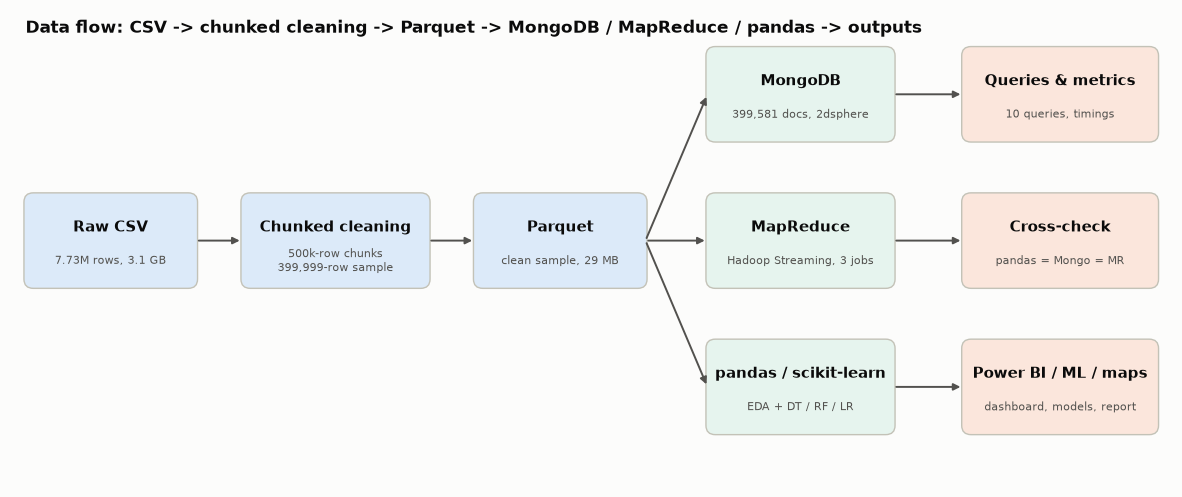

In [11]:
fig, ax = plt.subplots(figsize=(15, 6.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 6.2); ax.axis("off")
def box(x, y, w, h, title, sub, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=color, ec=V.AXIS, lw=1))
    ax.text(x + w / 2, y + h * 0.64, title, ha="center", va="center", fontsize=10.5, fontweight="bold", color=V.INK)
    ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center", fontsize=8, color=V.INK2)
def arrow(x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color=V.INK2, lw=1.4))
L, B, O = "#dceaf9", "#e6f4ee", "#fbe6dc"
box(0.2, 2.6, 2.2, 1.2, "Raw CSV", f"{stats_['total_rows'] / 1e6:.2f}M rows, {raw_gb:.1f} GB", L)
box(3.0, 2.6, 2.4, 1.2, "Chunked cleaning", "500k-row chunks" + chr(10) + f"{stats_['sample_rows']:,}-row sample", L)
box(6.0, 2.6, 2.2, 1.2, "Parquet", f"clean sample, {pq_mb:.0f} MB", L)
box(9.0, 4.5, 2.4, 1.2, "MongoDB", f"{load_info['documents']:,} docs, 2dsphere", B)
box(9.0, 2.6, 2.4, 1.2, "MapReduce", "Hadoop Streaming, 3 jobs", B)
box(9.0, 0.7, 2.4, 1.2, "pandas / scikit-learn", "EDA + DT / RF / LR", B)
box(12.3, 4.5, 2.5, 1.2, "Queries & metrics", f"{mres['n_queries']} queries, timings", O)
box(12.3, 2.6, 2.5, 1.2, "Cross-check", "pandas = Mongo = MR" if cross["mapreduce_matches_pandas"] and cross["mongodb_matches_pandas"] else "mismatch found", O)
box(12.3, 0.7, 2.5, 1.2, "Power BI / ML / maps", "dashboard, models, report", O)
arrow(2.4, 3.2, 3.0, 3.2); arrow(5.4, 3.2, 6.0, 3.2)
for yy in (5.1, 3.2, 1.3):
    arrow(8.2, 3.2, 9.0, yy); arrow(11.4, yy, 12.3, yy)
ax.text(0.2, 5.9, "Data flow: CSV -> chunked cleaning -> Parquet -> MongoDB / MapReduce / pandas -> outputs", fontsize=12, fontweight="bold", color=V.INK)
V.save(fig, FIG / "data_flow.png")

## Module 5 summary
MongoDB stores every cleaned accident as a GeoJSON document; indexes turn selective filters from full scans into
index scans, and `$geoNear` answers radius questions around hotspots. The three MapReduce jobs reproduce the pandas
aggregations exactly, as do the MongoDB aggregations (see `reports/metrics/crosscheck_summary.json`). The real
Hadoop cluster and Spark runs are documented as optional and were not executed.